In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [ ]:
df = pd.read_csv("Pharma_Industry.csv")
df.shape


(500, 6)

In [ ]:
df.isnull().sum()

,0
Drug Dosage (mg),0
Systolic Blood Pressure (mmHg),0
Heart Rate (BPM),0
Liver Toxicity Index (U/L),0
Blood Glucose Level (mg/dL),0
Drug Response,0


In [ ]:
df.head()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.866786,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1


In [ ]:
X = df.iloc[:,0:5]
y = df["Drug Response"]

In [ ]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# Define SVM models with different kernels
svm_linear = SVC(kernel='linear', C=1.0)
svm_poly = SVC(kernel='poly', degree=3, C=1.0)
svm_rbf = SVC(kernel='rbf', gamma=0.5, C=1.0)

In [ ]:
# Train and evaluate SVM with linear kernel
svm_linear.fit(X_train, y_train)
y_pred_linear = svm_linear.predict(X_test)
accuracy_linear = accuracy_score(y_test, y_pred_linear)
accuracy_linear

0.7066666666666667

In [ ]:
# Train and evaluate SVM with polynomial kernel
svm_poly.fit(X_train, y_train)
y_pred_poly = svm_poly.predict(X_test)
accuracy_poly = accuracy_score(y_test, y_pred_poly)
accuracy_poly

0.72

In [ ]:
# Train and evaluate SVM with RBF kernel
svm_rbf.fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
accuracy_rbf

0.82

In [ ]:
# Display results
print(f"Linear SVM Accuracy: {accuracy_linear:.2f}")
print(f"Polynomial SVM Accuracy: {accuracy_poly:.2f}")
print(f"RBF SVM Accuracy: {accuracy_rbf:.2f}")

Linear SVM Accuracy: 0.71
Polynomial SVM Accuracy: 0.72
RBF SVM Accuracy: 0.82


In [ ]:
%matplotlib inline
#plot_3d_decision_boundary_fixed(svm_linear, X_train.values, y_train, "3D Decision Boundary - Linear SVM")

In [ ]:
'''
%matplotlib qt
plot_3d_decision_boundary_fixed(svm_linear, X_train.values, y_train, "3D Decision Boundary - Linear SVM")

%matplotlib qt
plot_3d_decision_boundary_fixed(svm_poly, X_train.values, y_train, "3D Decision Boundary - Linear SVM")

%matplotlib qt
plot_3d_decision_boundary_fixed(svm_rbf, X_train.values, y_train, "3D Decision Boundary - Linear SVM")
'''

'\n%matplotlib qt\nplot_3d_decision_boundary_fixed(svm_linear, X_train.values, y_train, "3D Decision Boundary - Linear SVM")\n\n%matplotlib qt\nplot_3d_decision_boundary_fixed(svm_poly, X_train.values, y_train, "3D Decision Boundary - Linear SVM")\n\n%matplotlib qt\nplot_3d_decision_boundary_fixed(svm_rbf, X_train.values, y_train, "3D Decision Boundary - Linear SVM")\n'

In [ ]:
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial import Delaunay # used to perform Delaunay Triangulation, which divides a set of points into 
#triangles such that no point lies inside the circumcircle of any triangle.

pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X)



In [ ]:
X_pca_3d

array([[ 0.09588785, -1.18481881, -0.77979571],
       [ 3.12744002, -1.07573416, -1.93317756],
       [-1.84541943,  0.63422856, -0.88169527],
       ...,
       [-0.1150928 ,  0.35309438, -0.77532662],
       [ 0.76060378,  0.95774289,  0.57360702],
       [-0.04569623, -0.69267294, -0.68776687]])

In [ ]:
# Train SVM Models on 3D Transformed Data
svm_linear_3d = SVC(kernel='linear', C=1.0)
svm_linear_3d.fit(X_pca_3d, y)

svm_poly_3d = SVC(kernel='poly', degree=3, C=1.0)
svm_poly_3d.fit(X_pca_3d, y)

svm_rbf_3d = SVC(kernel='rbf', gamma=0.5, C=1.0)
svm_rbf_3d.fit(X_pca_3d, y)

SVC(gamma=0.5)

In [ ]:
# Step 6: Function to Plot 3D Decision Boundaries
def plot_3d_decision_boundary_fixed(model, X, y, title):
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    # Scatter plot of data points
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y, cmap=plt.cm.Paired, edgecolor='k')

    # Create a triangulation of the feature space
    tri = Delaunay(X[:, :2])

    # Predict values for the 3D surface
    Z = model.decision_function(X)

    # Create surface plot
    ax.plot_trisurf(X[:, 0], X[:, 1], Z, triangles=tri.simplices, cmap='coolwarm', alpha=0.3)

    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.set_zlabel('Decision Boundary')
    ax.set_title(title)

    plt.show()

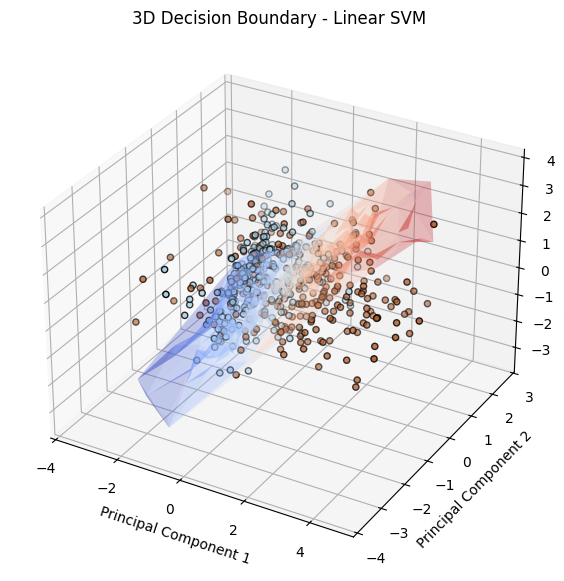

In [ ]:
# Step 7: Plot Decision Boundaries for Each Model
%matplotlib inline
plot_3d_decision_boundary_fixed(svm_linear_3d, X_pca_3d, y, "3D Decision Boundary - Linear SVM")

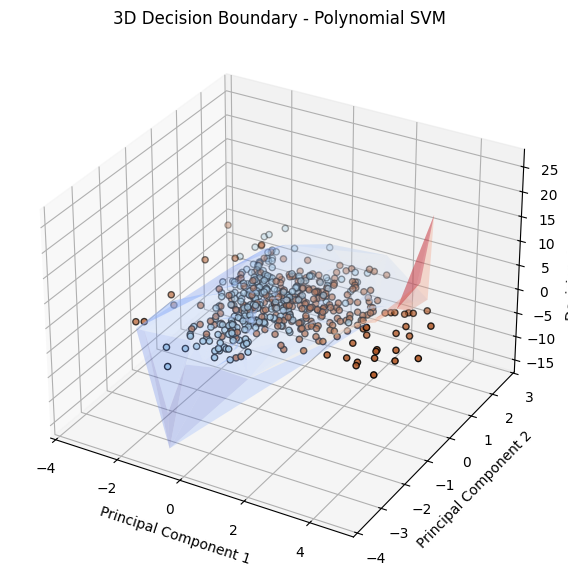

In [ ]:
plot_3d_decision_boundary_fixed(svm_poly_3d, X_pca_3d, y, "3D Decision Boundary - Polynomial SVM")

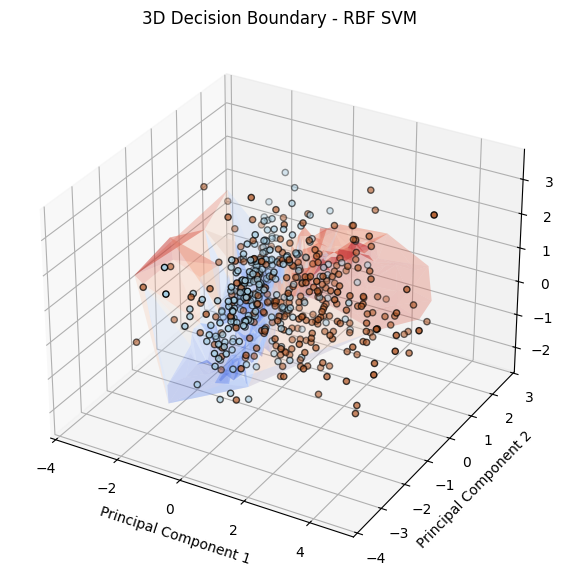

In [ ]:
plot_3d_decision_boundary_fixed(svm_rbf_3d, X_pca_3d, y, "3D Decision Boundary - RBF SVM")



# Hyperparameter Tuning

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
svc=SVC()
param=[{"kernel":["linear","ploy",'rbf'],
        "C": [0,0.1,0.001,1,0.5],
        "gamma": ['scale',10,0.5,0.10,0.25,1.5]}]
grid=GridSearchCV(estimator=svc,param_grid=param)
grid.fit(X,y)

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
210 fits failed out of a total of 450.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
90 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.12/dist-packages/sklearn/utils

GridSearchCV(estimator=SVC(),
             param_grid=[{'C': [0, 0.1, 0.001, 1, 0.5],
                          'gamma': ['scale', 10, 0.5, 0.1, 0.25, 1.5],
                          'kernel': ['linear', 'ploy', 'rbf']}])

In [ ]:
grid.best_score_,grid.best_params_

(np.float64(0.76), {'C': 0.5, 'gamma': 0.25, 'kernel': 'rbf'})